# Belebele: investigate invalid responses and wrong answers

Read the completed run and inspect its mistakes. **No new inference, score changes, or model-weight loading.** Default cells use saved results plus the pinned dataset text already in the Hugging Face cache. The optional input-preview cell renders one selected example in memory and loads only its cached processor, on CPU.

Run all cells using the project `.venv` kernel. Your existing evaluation and overview notebooks are separate and unchanged. The notebook is saved clean: charts and example images appear only when cells run; clear outputs before saving/sharing.

In [1]:
from pathlib import Path
from html import escape
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
from rendering_eval.error_analysis import ErrorExplorer, CASE_STUDIES, plot_error_patterns
from rendering_eval.reporting import LANGUAGE_NAMES

RESULTS_DIR = Path("results/belebele-full-4bit")
explorer = ErrorExplorer(RESULTS_DIR)
diagnosis = explorer.diagnosis()
plot_handles = []
def show_plot(figure):
    plot_handles.append(display(figure, display_id=True))
    plt.close(figure)

print(f"{diagnosis['image_errors']:,} image errors: "
      f"{diagnosis['valid_wrong_image']:,} valid wrong choices + {diagnosis['invalid_image']} invalid responses")
print(f"If EVERY invalid image response became correct: "
      f"{diagnosis['image_accuracy_pct']:.2f}% → {diagnosis['all_invalid_correct_upper_bound_pct']:.2f}% "
      f"(+{diagnosis['max_gain_from_invalid_pp']:.2f} points at most).")

7,063 image errors: 7,014 valid wrong choices + 49 invalid responses
If EVERY invalid image response became correct: 34.60% → 35.06% (+0.45 points at most).


## Why are they invalid?

The instruction asks for one A–D letter. Generation is **greedy but unconstrained**: it can emit arbitrary words, not just A–D. The scorer accepts a single letter, allowing case differences, `(A)`, or `A.`. It does not infer a choice from prose.

All 49 invalid responses in this run start prose and reach **16 generated tokens**, without a usable answer. They include 47 descriptions/preambles, one claim of incomplete input, and one request for the passage. The 19 distinct raw strings are shown below. These are output-format failures plus truncation, rather than simple punctuation that the scorer rejected.

Thinking was disabled in the prompt template; that setting does not constrain the final response to a letter. The saved outputs establish what was emitted, but cannot reveal whether a longer budget would eventually produce a correct answer. Extending the budget or forcing A–D decoding would be a **new experiment**, not a reason to change these scores.

In [2]:
invalid = pd.DataFrame(diagnosis["invalid_details"])
display(pd.Series(diagnosis["invalid_behavior_counts"], name="Count").to_frame())
summary = invalid.groupby("language").agg(
    Invalid=("sample_id", "size"),
    Same_language_text_correct=("text_correct", "sum"),
    English_image_correct=("english_image_correct", "sum"),
    Generated_tokens_min=("generated_tokens", "min"),
    Generated_tokens_max=("generated_tokens", "max"),
).rename(index=LANGUAGE_NAMES)
display(summary)
print(f"Same-language text was correct for {invalid.text_correct.sum()}/{len(invalid)} invalid-image cases.")
display(invalid.groupby("raw_response", sort=False).size().rename("Count").to_frame().style.set_properties(
    **{"white-space": "pre-wrap", "text-align": "left"}))
# Full unmodified output for every invalid row. IDs can be copied into the browser below.
display(invalid[["sample_id", "language", "gold", "raw_response", "behavior", "generated_tokens",
                 "text_correct", "english_image_correct"]].style.format(escape="html").set_properties(
    **{"white-space": "pre-wrap", "text-align": "left"}))

,Count
prose instead of a choice; token limit,47
claims incomplete input; token limit,1
requests passage; token limit,1


,Invalid,Same_language_text_correct,English_image_correct,Generated_tokens_min,Generated_tokens_max
language,,,,,
Arabic (MSA),2,1,1,16,16
Khmer,3,1,2,16,16
Burmese,44,34,33,16,16


Same-language text was correct for 36/49 invalid-image cases.


,Count
raw_response,
The user has provided an image containing a passage in the Burmese language and a multiple,6
The user has provided an image containing a passage in Burmese script and a multiple-,2
The provided text is in the Burmese language. To answer the multiple-choice question,12
"The user has provided a passage in Burmese and a multiple-choice question format,",4
The provided text is in Burmese and appears to be a passage from a religious or,1
The provided text is in Khmer. I need to translate and understand the passage to,2
"The user has provided a passage in Burmese and a multiple-choice question, but",4
The user has provided an image containing a passage in Burmese and a multiple-choice,3
The user has provided a passage in the Burmese language and a multiple-choice question,2


,sample_id,language,gold,raw_response,behavior,generated_tokens,text_correct,english_image_correct
0,730f3ed99a381f18d12380fa4fc2f409d2f4e7422f4fabb6cc86363aaf95617c,mya_Mymr,C,The user has provided an image containing a passage in the Burmese language and a multiple,prose instead of a choice; token limit,16,False,False
1,752d9f860b07a17f703041e9dab9e9a146823d0e5afae84627f863687298aaf0,mya_Mymr,D,The user has provided an image containing a passage in Burmese script and a multiple-,prose instead of a choice; token limit,16,False,False
2,a4873282772940b73f230b0cafe863775baf43eb073fa4e1a197291f0f39122c,mya_Mymr,C,The provided text is in the Burmese language. To answer the multiple-choice question,prose instead of a choice; token limit,16,True,False
3,3992ab13cda38f5cda150eaed43a83d63f9dd6c80c55713668c0135b1b93165e,mya_Mymr,C,"The user has provided a passage in Burmese and a multiple-choice question format,",prose instead of a choice; token limit,16,True,True
4,8f738c60eba9af03398618e1fc244801da4d1b71bf2d42bb8444900e6cb13fec,mya_Mymr,B,The user has provided an image containing a passage in the Burmese language and a multiple,prose instead of a choice; token limit,16,True,True
5,53543f6f7c73311e359893d9889067b1e87f0d1fffbead86660b50b20f80559e,mya_Mymr,C,The user has provided an image containing a passage in the Burmese language and a multiple,prose instead of a choice; token limit,16,True,True
6,bc8c26b3f2a1e5886eb0a814e1b5fcb903d1cb5aa5811f3358735fe5f7e427c5,mya_Mymr,B,The provided text is in Burmese and appears to be a passage from a religious or,prose instead of a choice; token limit,16,True,True
7,db6fc973a4cc3e26748f2b167845dac2dd6ed1801b464df57613c8e8d87f695e,khm_Khmr,B,The provided text is in Khmer. I need to translate and understand the passage to,prose instead of a choice; token limit,16,False,True
8,9fc4b373dc484b47e5a0705efbee6fab8e128700db08cc9ff5aa1ff1e9daf4fa,mya_Mymr,C,The user has provided an image containing a passage in Burmese script and a multiple-,prose instead of a choice; token limit,16,True,True
9,3ab1cef6a39b65508b341dcc43f14d671062629737561014de83f01bba9ea266,mya_Mymr,D,The user has provided an image containing a passage in the Burmese language and a multiple,prose instead of a choice; token limit,16,True,True


## Most mistakes are valid wrong choices

**99.3% of image errors are valid wrong answers.** The heatmaps condition on the gold label, making answer-choice preferences visible rather than averaging them away. The confusion matrices show where correct labels go.

Khmer image accuracy is 87.9% for gold A but 3.6% for gold B. Arabic image accuracy is 72.1% for gold B but only 6.6–13.1% for the other labels. This is consistent with their strong A/B output preferences. Correct-label groups also contain different questions, so answer-order permutations would be needed to establish a causal position effect.

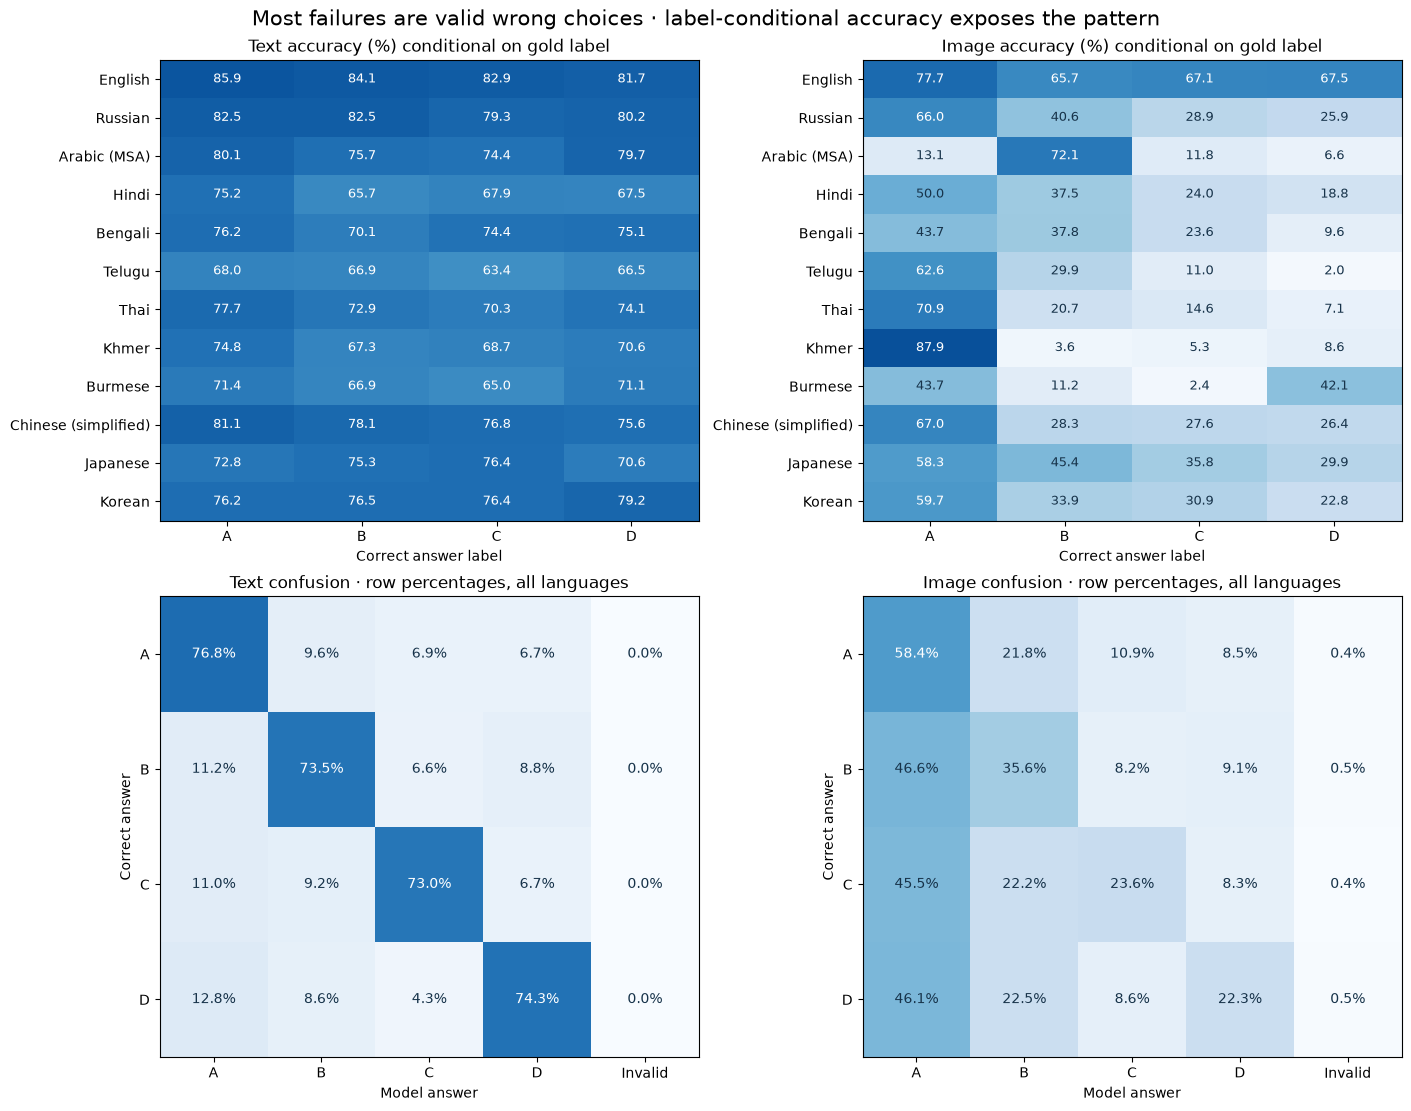

,Language,text_wrong,image_valid_wrong,image_invalid,wrong_image_most_common_choice,wrong_image_most_common_choice_n,Dominant_choice_share_of_valid_errors_%
0,English,147,277,0,A,138,49.82
1,Russian,170,540,0,A,337,62.41
2,Arabic (MSA),205,648,2,B,452,69.75
3,Hindi,280,607,0,A,308,50.74
4,Bengali,236,638,0,A,279,43.73
5,Telugu,305,665,0,A,418,62.86
6,Thai,238,652,0,A,465,71.32
7,Khmer,269,677,3,A,594,87.74
8,Burmese,285,649,44,D,287,44.22
9,Chinese (simplified),199,571,0,A,345,60.42


In [3]:
show_plot(plot_error_patterns(diagnosis))
errors = pd.DataFrame(diagnosis["language_errors"])
errors["Language"] = errors.language.map(LANGUAGE_NAMES)
errors["Dominant_choice_share_of_valid_errors_%"] = (
    100 * errors.wrong_image_most_common_choice_n / errors.image_valid_wrong)
display(errors[["Language", "text_wrong", "image_valid_wrong", "image_invalid",
                "wrong_image_most_common_choice", "wrong_image_most_common_choice_n",
                "Dominant_choice_share_of_valid_errors_%"]].round(2))

## Did missing input or page shrinkage cause the invalid responses?

Three invalid cases were rerendered and inspected alongside their actual processor-patch reconstructions: Burmese asking for the passage, Arabic claiming incomplete input, and Khmer describing translation. In all three, the **passage, question, and all four choices were present**, with no visible boundary clipping or missing-glyph boxes. Render and processor metadata matched the saved run. This is a layout check, not native-speaker validation of every glyph.

The Khmer invalid example was **upsized from 1024 × 528 to 1104 × 576**, so it did not fail because that page was shrunk. The Arabic page was 1024 × 711 → 960 × 624; the Burmese page was 1024 × 817 → 864 × 672. The model's statement that input is missing/incomplete is not reliable evidence that the pipeline omitted it.

Across all affected languages, invalid pages have lower median heights than valid pages below. Short cases can fail too. This rules out a simple “only the tallest/smallest pages fail” account; it does not determine the model's internal failure mechanism.

In [4]:
comparison = pd.DataFrame(diagnosis["invalid_comparisons"])
comparison.insert(0, "Language", comparison.language.map(LANGUAGE_NAMES))
display(comparison.drop(columns="language").round(2))

,Language,invalid_n,valid_n,invalid_height_median,valid_height_median,invalid_text_correct,invalid_nominal_size_median,valid_nominal_size_median
0,Arabic (MSA),2,898,864.0,941.0,1,19.53,19.12
1,Khmer,3,897,577.0,682.0,1,23.96,21.96
2,Burmese,44,856,1135.0,1294.0,34,16.88,15.75


## Eight concrete cases: click a title to expand

These examples are selected to illustrate different outcomes, **not a random sample**. Each card includes the pinned English reference passage/question/options, original raw predictions in the tested language and English, and a short reading of the case. The gold answer is shown only for analysis; it was never included in the evaluation prompts. All cached source records are verified against manifest hashes and saved answer labels before display.

In [5]:
cards = []
for study in CASE_STUDIES:
    detail = explorer.case(study["sample_id"], study["language"])
    reference = detail["english"] or detail["example"]
    table = pd.DataFrame(detail["comparison"])[
        ["language", "mode", "gold", "raw_response", "correct", "valid", "truncated"]]
    cards.append(
        f"<details style='margin:12px 0;padding:10px;border:1px solid #ccc'>"
        f"<summary><b>{escape(study['title'])}</b></summary>"
        f"<p>{escape(study['note'])}</p>"
        f"<p><b>English reference:</b></p><pre style='white-space:pre-wrap'>{escape(reference.task_text())}</pre>"
        f"<p>Gold: <b>{reference.answer}</b></p>" + table.to_html(index=False, escape=True) +
        f"<p>Sample ID: <code>{study['sample_id']}</code></p></details>"
    )
display(HTML("".join(cards)))

language,mode,gold,raw_response,correct,valid,truncated
mya_Mymr,text,A,A,True,True,False
mya_Mymr,image,A,I need the passage to answer the multiple-choice question. Please provide the passage,False,False,True
eng_Latn,text,A,A,True,True,False
eng_Latn,image,A,A,True,True,False
language,mode,gold,raw_response,correct,valid,truncated
arb_Arab,text,A,A,True,True,False
arb_Arab,image,A,"The provided text is a passage in Arabic, but it is incomplete and the multiple",False,False,True
eng_Latn,text,A,A,True,True,False
eng_Latn,image,A,A,True,True,False
language,mode,gold,raw_response,correct,valid,truncated


## Browse any error, with its actual source text

Choose a curated case (0–7), or set `CASE_SOURCE = "browse"` and filter by language/outcome. Outcomes are `invalid image`, `text only`, `image only`, `both wrong`, and `both correct`. Browsing is deterministic by sample ID; no inference runs. Change the settings and rerun this cell, then the next source-display cell.

In [6]:
CASE_SOURCE = "browse"  # "curated" or "browse"
CURATED_CASE = 0
BROWSE_LANGUAGE = "arb_Arab"
BROWSE_OUTCOME = "invalid image"
BROWSE_INDEX = 0

if CASE_SOURCE == "curated":
    selected = CASE_STUDIES[CURATED_CASE]
    SAMPLE_ID, LANGUAGE = selected["sample_id"], selected["language"]
    display(Markdown(f"**{selected['title']}**  \n{selected['note']}"))
elif CASE_SOURCE == "browse":
    candidates = explorer.pairs[(explorer.pairs.language == BROWSE_LANGUAGE) &
                               (explorer.pairs.outcome == BROWSE_OUTCOME)].sort_values("sample_id")
    print(f"{len(candidates)} matching cases; selected index {BROWSE_INDEX}")
    if not 0 <= BROWSE_INDEX < len(candidates):
        raise ValueError("BROWSE_INDEX is outside the available cases")
    row = candidates.iloc[BROWSE_INDEX]
    SAMPLE_ID, LANGUAGE = row.sample_id, row.language
    display(candidates[["sample_id", "answer", "text_predicted", "image_predicted", "render_height"]].head(20))
else:
    raise ValueError("CASE_SOURCE must be curated or browse")
print("Selected:", LANGUAGE, SAMPLE_ID)

2 matching cases; selected index 0


,sample_id,answer,text_predicted,image_predicted,render_height
1308,20fe38e977b81e084ad76c78caa1cb5baeb86f2d0ac916...,A,A,NaN,711
7584,b0fae1c67a2efd3316ae8cf180a6ab851c4b498892d4cf...,D,C,NaN,1017


Selected: arb_Arab 20fe38e977b81e084ad76c78caa1cb5baeb86f2d0ac916f8a49b764190839992


In [7]:
detail = explorer.case(SAMPLE_ID, LANGUAGE)
example = detail["example"]
print("Gold:", example.answer, "—", example.choices["ABCD".index(example.answer)])
display(pd.DataFrame(detail["comparison"]).style.format(escape="html").set_properties(
    **{"white-space": "pre-wrap", "text-align": "left"}))
display(HTML(f"<h4>Actual {escape(LANGUAGE)} input text</h4>"
             f"<pre dir='auto' style='white-space:pre-wrap;font-size:16px'>{escape(example.task_text())}</pre>"))
if detail["english"] is not None and LANGUAGE != "eng_Latn":
    display(HTML("<details><summary>Aligned English reference</summary>"
                 f"<pre style='white-space:pre-wrap'>{escape(detail['english'].task_text())}</pre></details>"))

Gold: A — المساحات الخضراء الحضرية


,language,mode,gold,raw_response,correct,valid,truncated,generated_tokens,source_height,processed_width,processed_height
0,arb_Arab,text,A,A,True,True,False,2,nan,nan,nan
1,arb_Arab,image,A,"The provided text is a passage in Arabic, but it is incomplete and the multiple",False,False,True,16,711.000000,960.000000,624.000000
2,eng_Latn,text,A,A,True,True,False,2,nan,nan,nan
3,eng_Latn,image,A,A,True,True,False,2,528.000000,1104.000000,576.000000


## Optional: original rendering and actual processor input

Set the flag below to `True` to inspect **one selected case**. This uses the cached processor on CPU, with no model weights or inference. Fonts must be available from the evaluation setup. The processor comes strictly from the local cache. Images are rendered on demand, displayed, and released; rerunning replaces the previous case display.

Compare this with the model's claim about missing/incomplete text. Use the original overview notebook for broad language statistics. No chart or benchmark image files are saved.

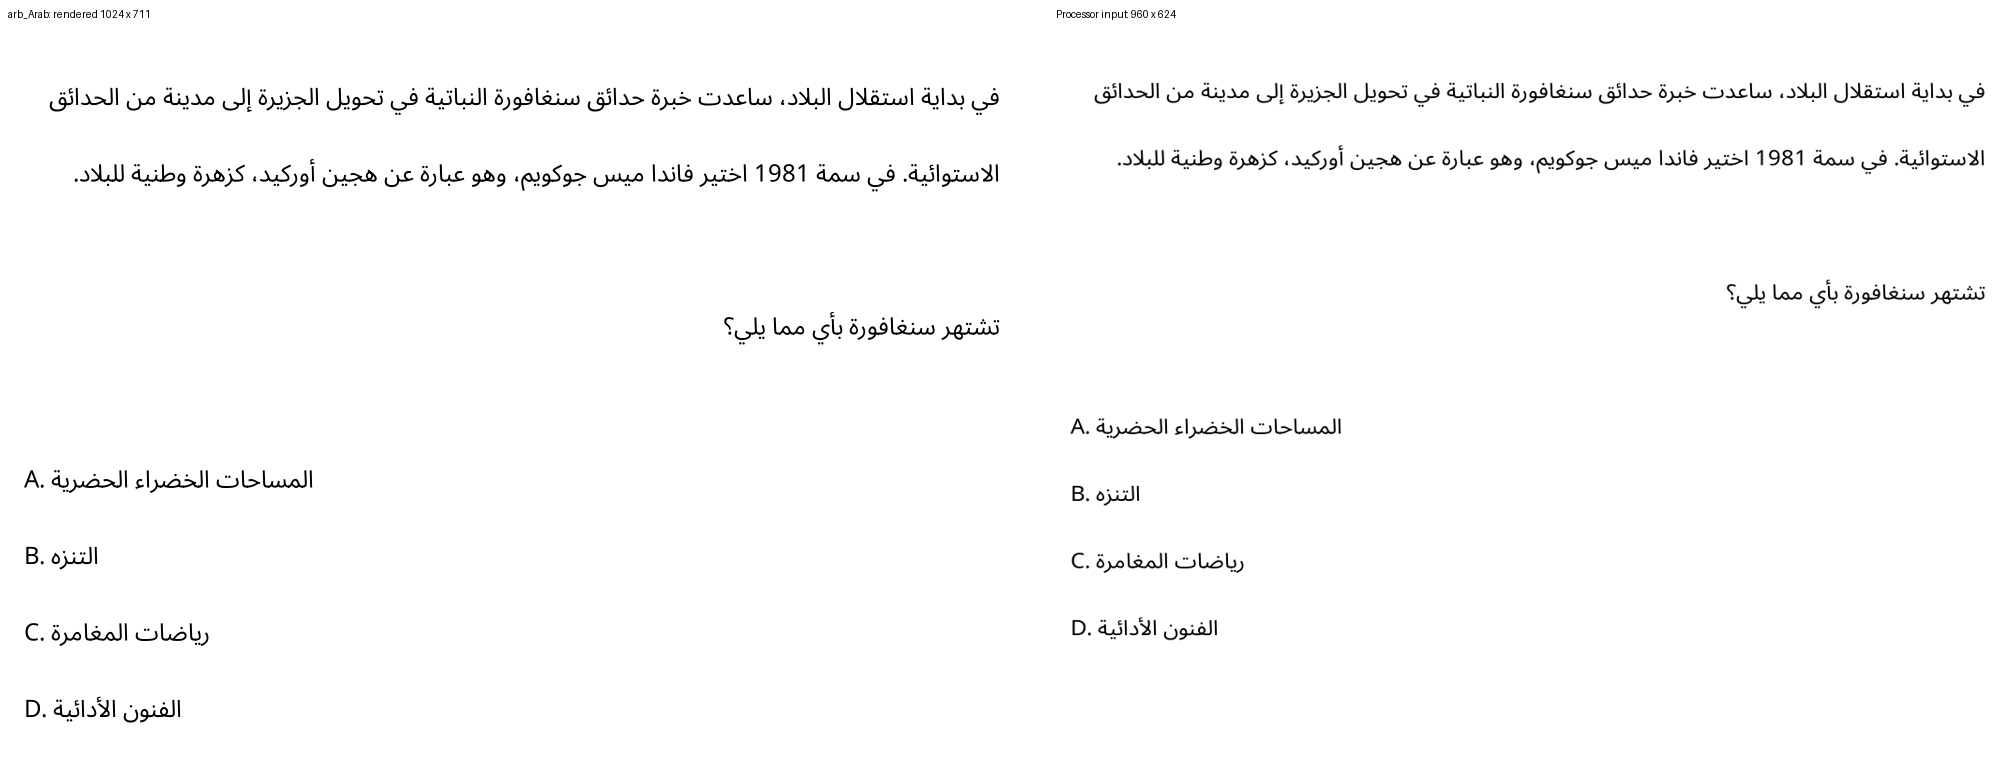

Rendering and processor metadata match the evaluated example.


In [8]:
SHOW_INPUT_PREVIEW = True  # Opt in to the processor-only, in-memory preview.
if SHOW_INPUT_PREVIEW:
    from transformers import AutoProcessor
    from rendering_eval.rendering import DocumentRenderer
    from rendering_eval.preview import preview_example
    cfg = explorer.config()
    if "case_processor" not in globals():
        case_processor = AutoProcessor.from_pretrained(
            cfg.model_id, revision=cfg.model_revision, local_files_only=True)
        case_processor.image_processor.max_soft_tokens = cfg.max_soft_tokens
        case_renderer = DocumentRenderer(cfg)
    if "case_preview_handle" in globals():
        case_preview_handle.update("Previous case cleared.")
    case_preview_handle, metadata = preview_example(
        cfg, explorer.sources()[SAMPLE_ID, LANGUAGE], renderer=case_renderer, processor=case_processor)
    plot_handles.append(case_preview_handle)
    saved = explorer.index[SAMPLE_ID, LANGUAGE, "image"]
    assert all(metadata[k] == value for k, value in saved["rendering"].items())
    assert all(metadata[k] == saved["inference"][k] for k in (
        "processed_width", "processed_height", "real_patches", "padded_patches", "soft_tokens"))
    print("Rendering and processor metadata match the evaluated example.")
else:
    print("Input preview disabled; default analysis loads no PyTorch or model.")

## What this investigation establishes

- **Invalid** means prose/preamble + token-limit exhaustion in this run. The scorer is not rejecting otherwise clean single-letter answers. All 49 were image responses; 36 had a correct same-language text answer.
- Even perfect recovery of invalid responses adds at most **0.45 accuracy points**. The 7,014 valid wrong image choices dominate the error total.
- There are strong label-dependent patterns, plus specific reading/selection errors. The Guinness example chooses the euro amount for a dollar question; the Vidal example shows the same origin/destination error in both modes; the nerve-impulse example shows an image-only success on a negated question.
- The inspected invalid inputs contain the passage, question, and all options. The selected short Khmer failure was upsampled. These observations narrow possible explanations but do not prove whether remaining failures arise from visual reading, instruction following, semantic reasoning, or quantization.

Useful next **separate** experiments: give invalid cases a longer answer budget; compare unconstrained with forced A–D decoding; permute choice order; increase the image-token budget on the same IDs. Keep original scores/results intact. None of those experiments runs in this notebook.

Before saving/sharing, clear outputs through the notebook menu or run:

```bash
.venv/bin/python scripts/clean_notebook.py Belebele_errors.ipynb
```

Use the next cell to replace live image/plot displays with text. Attribution and evaluation details are in [README](README.md).

In [9]:
CLEAR_PLOTS = False  # Set True before saving a clean notebook.
if CLEAR_PLOTS:
    for handle in plot_handles:
        handle.update("Display cleared; rerun its cell to inspect again.")
    plot_handles.clear()
    plt.close("all")